In [4]:
import os
import numpy as np
import wfdb
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

DATA_DIR = "../data/mitdb"
PRE, POST = 90, 110   # تعداد نمونه قبل و بعد از R-peak (در 360Hz حدود ۰٫۵۶ ثانیه)

def bandpass(sig, fs, low=0.5, high=40, order=3):
    b, a = butter(order, [low, high], btype="band", fs=fs)
    return filtfilt(b, a, sig)

In [5]:
AAMI = {}
for s in ["N", "L", "R", "e", "j"]: AAMI[s] = "N"
for s in ["A", "a", "J", "S"]:      AAMI[s] = "S"
for s in ["V", "E"]:                AAMI[s] = "V"
AAMI["F"] = "F"
for s in ["/", "f", "Q"]:           AAMI[s] = "Q"

CLASSES = ["N", "S", "V", "F", "Q"]

def extract_record(rec_id):
    record = wfdb.rdrecord(f"{DATA_DIR}/{rec_id}")
    ann = wfdb.rdann(f"{DATA_DIR}/{rec_id}", "atr")

    ch = record.sig_name.index("MLII")           # کانال MLII (جای آن در رکوردها فرق دارد)
    sig = bandpass(record.p_signal[:, ch], record.fs)

    # فقط نمادهایی که ضربان هستند
    keep = [i for i, s in enumerate(ann.symbol) if s in AAMI]
    samples = ann.sample[keep]
    labels = [AAMI[ann.symbol[i]] for i in keep]

    X, y, rr = [], [], []
    for k in range(1, len(samples) - 1):         # اولین و آخرین ضربان رو برای RR کنار می‌ذاریم
        p = samples[k]
        if p - PRE < 0 or p + POST > len(sig):
            continue
        X.append(sig[p - PRE : p + POST])
        y.append(CLASSES.index(labels[k]))
        rr.append([samples[k] - samples[k - 1], samples[k + 1] - samples[k]])

    groups = np.full(len(y), int(rec_id))
    return np.array(X), np.array(y), np.array(rr), groups

In [6]:
DS1 = [101,106,108,109,112,114,115,116,118,119,122,124,
       201,203,205,207,208,209,215,220,223,230]
DS2 = [100,103,105,111,113,117,121,123,200,202,210,212,
       213,214,219,221,222,228,231,232,233,234]

def build(ids):
    parts = [extract_record(str(r)) for r in ids]
    X  = np.concatenate([p[0] for p in parts])
    y  = np.concatenate([p[1] for p in parts])
    rr = np.concatenate([p[2] for p in parts])
    g  = np.concatenate([p[3] for p in parts])
    return X, y, rr, g

X_train, y_train, rr_train, g_train = build(DS1)
X_test,  y_test,  rr_test,  g_test  = build(DS2)

print("train:", X_train.shape, "| test:", X_test.shape)
for name, y in [("train", y_train), ("test", y_test)]:
    print(name, {c: int((y == i).sum()) for i, c in enumerate(CLASSES)})

train: (50977, 200) | test: (49668, 200)
train {'N': 45824, 'S': 943, 'V': 3788, 'F': 414, 'Q': 8}
test {'N': 44218, 'S': 1836, 'V': 3219, 'F': 388, 'Q': 7}


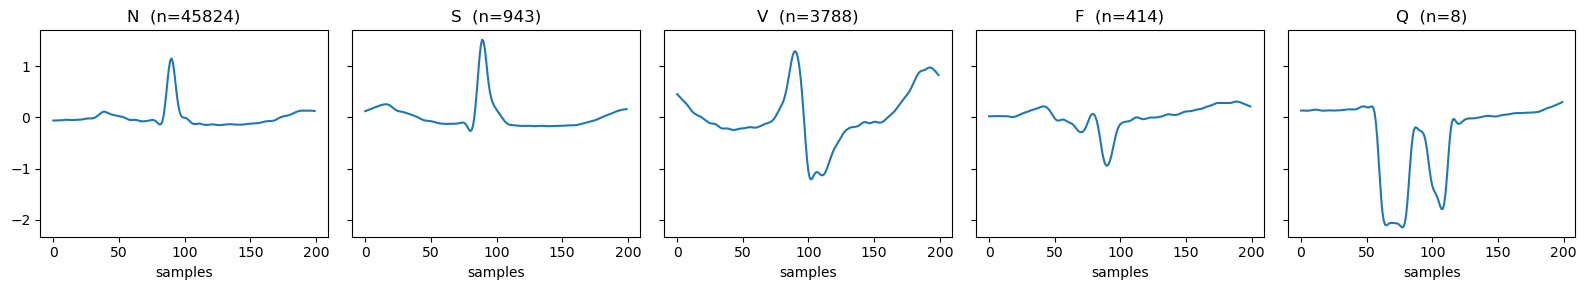

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharey=True)
for i, c in enumerate(CLASSES):
    idx = np.where(y_train == i)[0]
    if len(idx) == 0:
        continue
    axes[i].plot(X_train[idx[0]])
    axes[i].set_title(f"{c}  (n={len(idx)})")
    axes[i].set_xlabel("samples")
plt.tight_layout()
plt.show()

In [8]:
os.makedirs("../data/processed", exist_ok=True)
np.savez_compressed(
    "../data/processed/beats.npz",
    X_train=X_train, y_train=y_train, rr_train=rr_train, g_train=g_train,
    X_test=X_test,   y_test=y_test,   rr_test=rr_test,   g_test=g_test,
)
print("ذخیره شد")

ذخیره شد
